# Digital Divide in Rural vs. Urban Schools — Meta, Colombia (2019–2022)

**Question:** How did internet access and computer availability change in rural and urban school sites of the department of Meta before, during and after the COVID-19 pandemic?

**Data:** DANE, *EDU-Microdatos: Educación Formal* — school-site records for Meta, 2019–2022 ([source](https://microdatos.dane.gov.co/index.php/catalog/EDU-Microdatos)).

**Team (Talento Tech – Data Analysis program, Feb–Apr 2026):** Mayra Valentina Gamboa Zárate (research lead) · Jorge Manzur Salamanca Chidiak (technical lead) · Katherin Ortega Pertuz (data analyst) · Gisel Sthepfany Serna Montenegro (data analyst). This version was cleaned and re-verified by Mayra Valentina Gamboa Zárate.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats
from pathlib import Path

try:
    display
except NameError:            # outside Jupyter
    display = print

pd.set_option("display.precision", 2)
# Charts are saved next to the notebook

# Chart style: light surface, recessive axes, thin marks
URBAN, RURAL = "#2a78d6", "#eb6834"
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": INK_2, "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "font.size": 11, "axes.titlesize": 14, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "figure.dpi": 110, "savefig.dpi": 150,
    "savefig.bbox": "tight",
})

## 1. Load and inspect the data

| Column | Meaning |
| --- | --- |
| `SEDE_CODIGO` | Unique school-site code (Ministry of Education) |
| `PERIODO_ANIO` | Reference year (2019–2022) |
| `DEPTO`, `MUNI` | Department and municipality |
| `AREA_NOMBRE` | Rural or urban site |
| `SEDETE_INTERNET` | Site has internet access (1 = yes, 0 = no) |
| `SEDECOM_CANTIDAD` | Number of computers at the site |

In [2]:
df_raw = pd.read_csv("Data_Meta.csv")
print(df_raw.shape)
display(df_raw.head())

(3549, 7)


,SEDE_CODIGO,PERIODO_ANIO,DEPTO,MUNI,AREA_NOMBRE,SEDETE_INTERNET,SEDECOM_CANTIDAD
0,250350001944,2019,Meta,La Macarena,Rural,0.0,4.0
1,250568001172,2019,Meta,Puerto Gaitán,Rural,0.0,0.0
2,250450000031,2019,Meta,Puerto Concordia,Rural,0.0,9.0
3,150689000047,2019,Meta,San Martín,Urbana,1.0,7.0
4,250001002402,2019,Meta,Villavicencio,Rural,0.0,10.0


In [3]:
# Missing values by year: are they spread out or concentrated?
missing = (df_raw.set_index("PERIODO_ANIO")[["SEDETE_INTERNET", "SEDECOM_CANTIDAD"]]
           .isna().groupby(level=0).agg(["sum", "size"]))
display(missing)

SEDETE_INTERNET      SEDECOM_CANTIDAD     
                         sum size              sum size
PERIODO_ANIO                                           
2019                       0  877                0  877
2020                       0  887                0  887
2021                     896  900              896  900
2022                       0  885                0  885

## 2. Cleaning decisions

1. **Duplicates.** Exact duplicate rows are removed.
2. **2021 is excluded from rates, not filled with zeros.** 896 of the 900 site records for 2021 have no internet or computer data: the pandemic interrupted reporting. Filling them with 0 would invent "no internet, no computers" for almost every site and bias every average down. The 2021 gap is reported as a finding in itself.
3. **Text columns are left as they are.** `DEPTO`, `MUNI` and `AREA_NOMBRE` are already consistent, so no transformation is needed (and none should overwrite another column).

In [4]:
n_dups = df_raw.duplicated().sum()
df = df_raw.drop_duplicates().copy()
print(f"Exact duplicate rows removed: {n_dups}")

reported_2021 = df.loc[df.PERIODO_ANIO == 2021, "SEDETE_INTERNET"].notna().sum()
total_2021 = (df.PERIODO_ANIO == 2021).sum()
print(f"2021 records with data: {reported_2021} of {total_2021}")

# Analysis frame: years with complete reporting
an = df[df.PERIODO_ANIO != 2021].copy()
print("Analysis frame:", an.shape, "| missing values:", int(an.isna().sum().sum()))

Exact duplicate rows removed: 9
2021 records with data: 4 of 900
Analysis frame: (2640, 7) | missing values: 0


## 3. Who is in the data?

In [5]:
area_share = df.AREA_NOMBRE.value_counts(normalize=True).mul(100).round(1)
print("Share of site records by area (%):"); display(area_share)
print("Municipalities:", df.MUNI.nunique())

years_per_site = an.groupby("SEDE_CODIGO").PERIODO_ANIO.nunique()
panel_ids = years_per_site[years_per_site == 3].index
print(f"Sites observed in all three reported years (2019, 2020, 2022): {len(panel_ids)} "
      f"of {an.SEDE_CODIGO.nunique()}")

Share of site records by area (%):


AREA_NOMBRE
Rural     78.8
Urbana    21.2

Municipalities: 29
Sites observed in all three reported years (2019, 2020, 2022): 828 of 923


Meta's school network is overwhelmingly rural (about 4 in 5 site records). Most sites appear in every reported year, which lets us check later whether the trends hold for the *same* schools.

## 4. Internet access by area and year

In [6]:
internet = (an.groupby(["PERIODO_ANIO", "AREA_NOMBRE"]).SEDETE_INTERNET.mean()
              .unstack().mul(100).round(1))
internet["Gap (pts)"] = (internet["Urbana"] - internet["Rural"]).round(1)
display(internet)

overall_no_internet = (1 - an.groupby("PERIODO_ANIO").SEDETE_INTERNET.mean()).mul(100).round(1)
print("Sites without internet, all areas (%):"); display(overall_no_internet)

AREA_NOMBRE,Rural,Urbana,Gap (pts)
PERIODO_ANIO,,,
2019,19.7,63.0,43.3
2020,19.2,57.1,37.9
2022,41.7,68.1,26.4


Sites without internet, all areas (%):


PERIODO_ANIO
2019    71.1
2020    72.7
2022    52.8

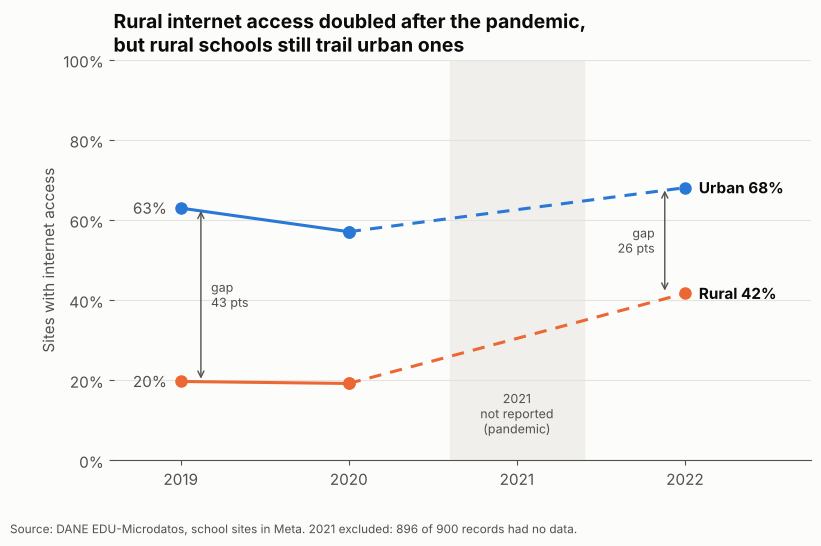

In [7]:
fig, ax = plt.subplots(figsize=(9, 5.2))
years = [2019, 2020, 2022]
for area, color, label in [("Urbana", URBAN, "Urban"), ("Rural", RURAL, "Rural")]:
    y = internet.loc[years, area]
    ax.plot([2019, 2020], y.loc[[2019, 2020]], color=color, lw=2.2, marker="o", ms=8)
    ax.plot([2020, 2022], y.loc[[2020, 2022]], color=color, lw=2.2, ls=(0, (4, 3)), marker="o", ms=8)
    ax.annotate(f"{label} {y.loc[2022]:.0f}%", (2022, y.loc[2022]), xytext=(10, 0),
                textcoords="offset points", va="center", color=INK, fontweight="bold")
    ax.annotate(f"{y.loc[2019]:.0f}%", (2019, y.loc[2019]), xytext=(-10, 0),
                textcoords="offset points", va="center", ha="right", color=INK_2)

ax.axvspan(2020.6, 2021.4, color="#f0efec", zorder=0)
ax.text(2021, 6, "2021\nnot reported\n(pandemic)", ha="center", va="bottom", color=INK_2, fontsize=9)

for yr in (2019, 2022):
    lo, hi = internet.loc[yr, "Rural"], internet.loc[yr, "Urbana"]
    x = yr + (0.12 if yr == 2019 else -0.12)
    ax.annotate("", (x, lo), (x, hi), arrowprops=dict(arrowstyle="<->", color=INK_2, lw=1))
    ax.text(x + (0.06 if yr == 2019 else -0.06), (lo + hi) / 2, f"gap\n{hi - lo:.0f} pts",
            ha="left" if yr == 2019 else "right", va="center", color=INK_2, fontsize=9)

ax.set_xticks([2019, 2020, 2021, 2022])
ax.set_xlim(2018.6, 2022.75)
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel("Sites with internet access")
ax.set_title("Rural internet access doubled after the pandemic,\nbut rural schools still trail urban ones")
fig.text(0.01, -0.03, "Source: DANE EDU-Microdatos, school sites in Meta. 2021 excluded: 896 of 900 records had no data.",
         color=INK_2, fontsize=8.5)
fig.savefig("01_internet_access.png")
plt.show()

In [8]:
# Is the rural-urban difference statistically significant each year? (chi-square test)
rows = []
for yr in years:
    table = pd.crosstab(an[an.PERIODO_ANIO == yr].AREA_NOMBRE, an[an.PERIODO_ANIO == yr].SEDETE_INTERNET)
    chi2, p, _, _ = stats.chi2_contingency(table)
    rows.append({"year": yr, "chi2": round(chi2, 1), "p_value": f"{p:.1e}"})
display(pd.DataFrame(rows))

# Did rural access change between 2019 and 2022?
rural = an[(an.AREA_NOMBRE == "Rural") & an.PERIODO_ANIO.isin([2019, 2022])]
chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(rural.PERIODO_ANIO, rural.SEDETE_INTERNET))
print(f"Rural 2019 vs 2022: chi2 = {chi2:.1f}, p = {p:.1e}")

,year,chi2,p_value
0,2019,130.2,3.7e-30
1,2020,106.0,7.2e-25
2,2022,39.8,2.7e-10


Rural 2019 vs 2022: chi2 = 77.3, p = 1.5e-18


**Reading:** urban sites were far more connected in every year (p < 0.001). Rural access stayed flat from 2019 to 2020 and then roughly doubled by 2022, a statistically significant change. The rural–urban gap narrowed but did not close.

## 5. Computers per site

In [9]:
pcs = an.groupby(["PERIODO_ANIO", "AREA_NOMBRE"]).SEDECOM_CANTIDAD.agg(
    sites="size", median="median", mean="mean",
    no_computers=lambda s: (s == 0).mean() * 100).round(1)
display(pcs)

by_area = an.groupby("AREA_NOMBRE").SEDECOM_CANTIDAD.agg(["median", "mean"]).round(1)
print("All reported years:"); display(by_area)

u = an[an.AREA_NOMBRE == "Urbana"].SEDECOM_CANTIDAD
r = an[an.AREA_NOMBRE == "Rural"].SEDECOM_CANTIDAD
res = stats.mannwhitneyu(u, r)
print(f"Mann-Whitney U (urban vs rural computers): p = {res.pvalue:.1e}")

sites  median  mean  no_computers
PERIODO_ANIO AREA_NOMBRE                                   
2019         Rural          684     2.0   3.2          38.7
             Urbana         184     5.0  12.4          14.1
2020         Rural          698     1.0   3.0          40.5
             Urbana         189     5.0  11.8          16.9
2022         Rural          700     0.0   2.7          52.1
             Urbana         185     5.0  13.1          20.5

All reported years:


,median,mean
AREA_NOMBRE,,
Rural,1.0,2.9
Urbana,5.0,12.4


Mann-Whitney U (urban vs rural computers): p = 1.0e-68


SEDECOM_CANTIDAD,0,1–5,6–15,16+
AREA_NOMBRE,,,,
Urbana,17.2,37.3,22.6,22.9
Rural,43.9,43.1,10.8,2.3


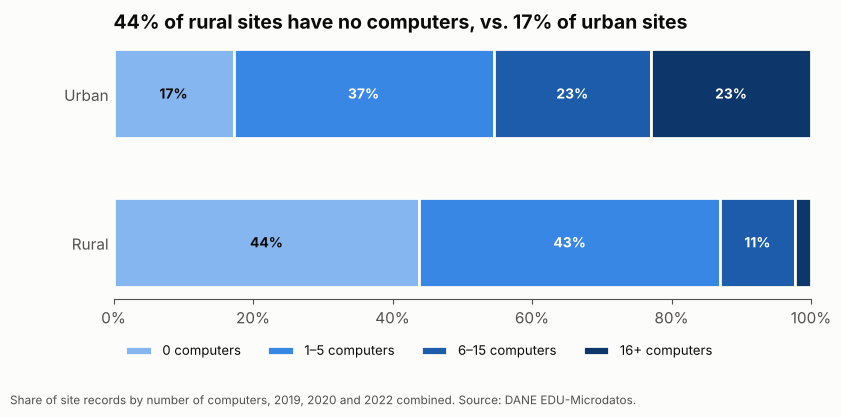

In [10]:
bands = pd.cut(an.SEDECOM_CANTIDAD, [-0.1, 0, 5, 15, np.inf], labels=["0", "1–5", "6–15", "16+"])
dist = pd.crosstab(an.AREA_NOMBRE, bands, normalize="index").mul(100).loc[["Urbana", "Rural"]]
display(dist.round(1))

ramp = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
fig, ax = plt.subplots(figsize=(9, 3.4))
left = np.zeros(len(dist))
for i, band in enumerate(dist.columns):
    vals = dist[band].values
    ax.barh(["Urban", "Rural"], vals, left=left, color=ramp[i], edgecolor="#fcfcfb", linewidth=2, height=0.6,
            label=f"{band} computers")
    for j, v in enumerate(vals):
        if v >= 6:
            ax.text(left[j] + v / 2, j, f"{v:.0f}%", ha="center", va="center", fontsize=10,
                    color=INK if i == 0 else "white", fontweight="bold")
    left += vals
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.grid(False)
ax.tick_params(axis="y", length=0)
ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, -0.12), frameon=False, fontsize=9.5)
zr, zu = dist.loc["Rural", "0"], dist.loc["Urbana", "0"]
ax.set_title(f"{zr:.0f}% of rural sites have no computers, vs. {zu:.0f}% of urban sites")
fig.text(0.01, -0.2, "Share of site records by number of computers, 2019, 2020 and 2022 combined. Source: DANE EDU-Microdatos.",
         color=INK_2, fontsize=8.5)
fig.savefig("02_computers_distribution.png")
plt.show()

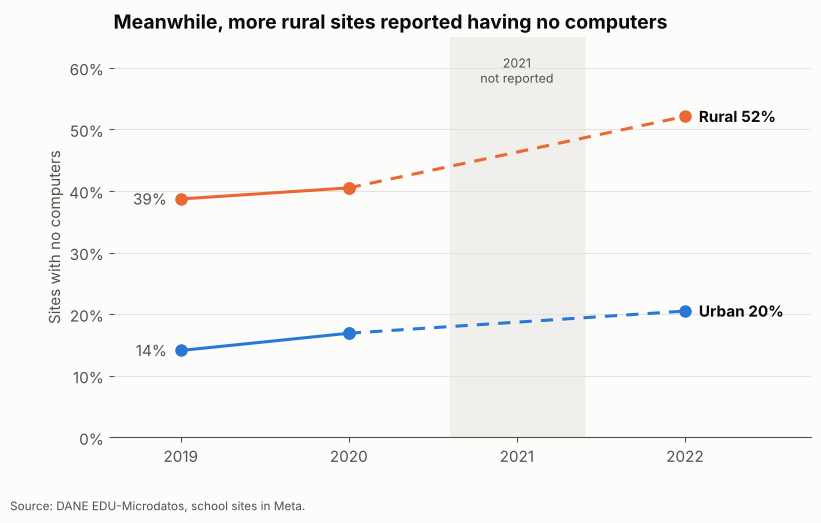

In [11]:
no_pc = pcs["no_computers"].unstack()
fig, ax = plt.subplots(figsize=(9, 5.2))
for area, color, label in [("Rural", RURAL, "Rural"), ("Urbana", URBAN, "Urban")]:
    y = no_pc.loc[years, area]
    ax.plot([2019, 2020], y.loc[[2019, 2020]], color=color, lw=2.2, marker="o", ms=8)
    ax.plot([2020, 2022], y.loc[[2020, 2022]], color=color, lw=2.2, ls=(0, (4, 3)), marker="o", ms=8)
    ax.annotate(f"{label} {y.loc[2022]:.0f}%", (2022, y.loc[2022]), xytext=(10, 0),
                textcoords="offset points", va="center", fontweight="bold")
    ax.annotate(f"{y.loc[2019]:.0f}%", (2019, y.loc[2019]), xytext=(-10, 0),
                textcoords="offset points", va="center", ha="right", color=INK_2)
ax.axvspan(2020.6, 2021.4, color="#f0efec", zorder=0)
ax.text(2021, 62, "2021\nnot reported", ha="center", va="top", color=INK_2, fontsize=9)
ax.set_xticks([2019, 2020, 2021, 2022])
ax.set_xlim(2018.6, 2022.75)
ax.set_ylim(0, 65)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel("Sites with no computers")
ax.set_title("Meanwhile, more rural sites reported having no computers")
fig.text(0.01, -0.03, "Source: DANE EDU-Microdatos, school sites in Meta.", color=INK_2, fontsize=8.5)
fig.savefig("03_sites_without_computers.png")
plt.show()

**Reading:** urban sites have a median of 5 computers against 1 in rural sites, and the difference is significant. While rural internet access improved, the share of rural sites reporting *zero* computers rose from 2019 to 2022. Connectivity and equipment moved in opposite directions.

## 6. Robustness: the same schools in every year

Changes between years could come from different schools entering or leaving the data. Repeating the key figures for the sites observed in all three reported years rules that out.

In [12]:
panel = an[an.SEDE_CODIGO.isin(panel_ids)]
robust = panel.groupby(["PERIODO_ANIO", "AREA_NOMBRE"]).agg(
    internet_pct=("SEDETE_INTERNET", lambda s: s.mean() * 100),
    no_computers_pct=("SEDECOM_CANTIDAD", lambda s: (s == 0).mean() * 100)).round(1)
display(robust)

pr = panel[panel.AREA_NOMBRE == "Rural"].pivot_table(index="SEDE_CODIGO", columns="PERIODO_ANIO",
                                                      values="SEDETE_INTERNET")
print(f"Rural panel sites that gained internet 2019→2022: {int(((pr[2019] == 0) & (pr[2022] == 1)).sum())}; "
      f"lost it: {int(((pr[2019] == 1) & (pr[2022] == 0)).sum())}")

internet_pct  no_computers_pct
PERIODO_ANIO AREA_NOMBRE                                
2019         Rural                19.7              37.9
             Urbana               63.8              13.0
2020         Rural                19.5              38.6
             Urbana               58.8              13.6
2022         Rural                42.7              50.2
             Urbana               68.5              19.0

Rural panel sites that gained internet 2019→2022: 176; lost it: 27


The same pattern holds for the fixed group of schools, so the trends are not an artifact of changes in the sample.

## 7. Conclusions

**Key findings**
- Sites without internet fell from 71% (2019) to 53% (2022). Most of the improvement came from rural sites, whose access rose from about 20% to about 42%.
- The rural–urban internet gap narrowed from 43 to 26 percentage points, but remains large and significant.
- Equipment did not follow connectivity: rural sites have a median of 1 computer (urban: 5), and the share of rural sites with no computers rose to about half by 2022.
- 2021 is a reporting blackout: 896 of 900 site records have no ICT data, a sign of how the pandemic disrupted education information systems.

**Limitations**
- Descriptive, not causal: the data cannot tell which programs drove the improvement.
- Internet access is a yes/no flag; it says nothing about speed or reliability.
- Computers are an absolute count, not per student, because enrollment is not in this dataset.
- A rising "zero computers" share could partly reflect changes in how sites report equipment; administrative records would be needed to confirm it.

**Recommendations**
1. Pair rural connectivity programs with device provision, since internet access alone is not translating into equipped schools.
2. Prioritize the rural sites that still have neither internet nor computers.
3. Strengthen ICT reporting so that a crisis year does not become a blind spot for policy.